Resources for analysis

* https://bioinformaticsworkbook.org/tutorials/wgcna.html#gsc.tab=0

## Set Library Path

In [1]:
.libPaths("/home/vhaghani/anaconda3/envs/jupyter_nb_R4.4.2/lib/R/library")

## Load Libraries

In [3]:
library(tidyverse)
library(WGCNA)
library(magrittr)
library(biomaRt)

## Load Data

In [4]:
# Read in normalized gene counts from DEG analysis
counts <- read.delim("05_gene_counts/MECP2_normalized_counts.txt", row.names = 1)

# Fix column naming
colnames(counts) <- gsub("^X", "", colnames(counts))

# View data
head(counts)

,CO_R270X_B1_d18_A1,CO_R270X_B1_d18_A2,CO_R270X_B1_d18_A3,CO_R270X_B1_d18_D1,CO_R270X_B1_d18_D2,CO_R270X_B1_d18_D3,CO_R270X_B1_d46_A1,CO_R270X_B1_d46_A2,CO_R270X_B1_d46_A3,CO_R270X_B1_d46_D1,⋯,CO_R270X_B2_d18_D2,CO_R270X_B2_d18_D3,CO_R270X_B2_d46_A3,CO_R270X_B2_d46_D1,CO_R270X_B2_d46_D2,CO_R270X_B2_d90_A1,CO_R270X_B2_d90_A2,CO_R270X_B2_d90_A3,CO_R270X_B2_d90_D2,CO_R270X_B2_d90_D3
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
A0A024R0Q4,1.4993548,1.709907,0.9498563,1.286680,2.653487,2.220239,1.3237572,1.6971443,1.8802670,1.9017521,⋯,0.5464109,1.091611,1.866634,1.64069089,0.32210956,1.9764955,1.6577710,1.030283,2.7174291,1.8688667
A0A024R5G2,6.4425835,6.546013,6.5974612,6.551987,6.287372,6.305753,6.3141910,6.0789388,6.2418120,6.1674039,⋯,6.8834004,6.884144,6.489503,6.23872537,7.20093485,5.8519384,6.0309275,6.019936,5.6347899,5.7874899
A0A024RAA5,0.9226547,1.709907,0.9498563,1.860137,2.844411,2.220239,2.7695670,2.4493727,3.2835161,3.2151098,⋯,1.6202625,1.851487,2.855741,2.83252181,2.08180265,2.4793032,2.1395255,1.030283,1.9797838,1.8688667
A0A024RAJ1,0.3499977,1.075803,1.1707078,1.452780,1.856415,1.997114,1.3237572,0.8181286,1.5890741,0.6585196,⋯,2.2290254,2.346622,1.104445,-0.05649679,-0.61370334,0.9754497,0.6705508,1.256801,0.9780829,0.8899348
A0A024RBW1,3.9881426,4.311162,3.9100470,4.385187,4.229247,4.460733,0.9158039,1.5224164,0.7336337,0.9159240,⋯,3.8850675,3.912662,1.743074,2.39909072,-0.07121338,1.3910102,1.9186644,2.551374,1.9797838,1.2944767
A0A024RDL5,3.1254953,2.818192,3.2631336,3.017170,2.583786,2.938163,4.2823166,4.7699795,4.0705951,3.9782829,⋯,3.6732715,3.305755,4.171094,3.82873364,4.46809880,4.5009207,3.5358985,4.621301,4.0108141,4.7572460


In [5]:
# Transpose for WGCNA
counts <- t(counts)

# Sort counts by row names
counts <- counts[order(rownames(counts)), ]

# View
head(counts)

,A0A024R0Q4,A0A024R5G2,A0A024RAA5,A0A024RAJ1,A0A024RBW1,A0A024RDL5,A0A075B6P9,A0A075B6T4,A0A087WT20,A0A087WT30,⋯,ZRANB2,ZSCAN18,ZSCAN25,ZSCAN29,ZSCAN30,ZSCAN5A,ZSWIM8,ZXDC,ZZEF1,ZZZ3
CO_R270X_B1_d18_A1,1.4993548,6.442584,0.9226547,0.3499977,3.988143,3.125495,3.404656,0.9226547,3.404656,0.3499977,⋯,6.580038,2.712246,1.4993548,3.175936,1.7858452,3.486872,3.317469,3.900864,2.568609,0.9226547
CO_R270X_B1_d18_A2,1.7099074,6.546013,1.7099074,1.0758033,4.311162,2.818192,2.876499,1.7099074,3.549274,0.3048245,⋯,6.572710,3.038486,1.7099074,3.229555,1.8327984,2.558091,3.398253,3.979939,1.832798,1.4274167
CO_R270X_B1_d18_A3,0.9498563,6.597461,0.9498563,1.1707078,3.910047,3.263134,4.110166,2.8164632,3.565286,0.3702744,⋯,6.504049,3.713213,2.5276134,2.527613,0.9498563,2.527613,3.263134,3.677629,2.265301,1.3621960
CO_R270X_B1_d18_D1,1.2866799,6.551987,1.8601370,1.4527800,4.385187,3.017170,3.389195,2.1774372,3.684687,0.8830568,⋯,6.565654,3.389195,1.9738360,3.304792,2.4373780,2.787645,3.429615,3.616292,1.601716,1.8601370
CO_R270X_B1_d18_D2,2.6534871,6.287372,2.8444112,1.8564149,4.229247,2.583786,3.012996,1.7330559,3.953383,0.6264691,⋯,6.795019,3.163927,0.6264691,2.902823,0.8801268,2.433386,3.646591,4.274193,1.598154,2.2654631
CO_R270X_B1_d18_D3,2.2202389,6.305753,2.2202389,1.9971145,4.460733,2.938163,3.502927,1.7330547,3.701098,0.4018654,⋯,6.720855,2.583784,1.7330547,2.220239,2.1129859,2.873911,3.273134,4.030727,1.871118,1.4095872


### Set Up Metadata

In [6]:
# Load WGCNA metadata
metadata <- read.csv("metadata.csv")

# Set row names
rownames(metadata) <- metadata$Sample_Name
metadata$Sample_Name <- NULL

# Clean up rows from DEG analysis
metadata$Gene <- NULL
metadata$Sample_ID <- NULL
metadata$Cell_Type <- NULL
metadata$Genotype <- NULL
metadata$Time_Point <- NULL
metadata$Group <- NULL
metadata$Replicate <- NULL
metadata$Clean_Sample_Name <- NULL
metadata$Batch <- NULL

# Remove comparisons we are not interested in 
metadata$D18_WT_vs_D46_WT <- NULL
metadata$D46_WT_vs_D90_WT <- NULL
metadata$D18_WT_vs_D90_WT <- NULL
metadata$D18_MUT_vs_D46_MUT <- NULL
metadata$D46_MUT_vs_D90_MUT <- NULL
metadata$D18_MUT_vs_D90_MUT <- NULL


# Sort metadata by row names
metadata <- metadata[order(rownames(metadata)), ]

# View
head(metadata)

,D18_MUT_vs_D18_WT,D46_MUT_vs_D46_WT,D90_MUT_vs_D90_WT,Decreased_GAD1_Expression,Decreased_FOXG1_Expression,Smaller_Organoid_Area,Impaired_Neurite_Outgrowth
,<int>,<int>,<int>,<int>,<int>,<int>,<int>
CO_R270X_B1_d18_A1,1,NA,NA,NA,1,NA,NA
CO_R270X_B1_d18_A2,1,NA,NA,NA,1,NA,NA
CO_R270X_B1_d18_A3,1,NA,NA,NA,1,NA,NA
CO_R270X_B1_d18_D1,0,NA,NA,NA,0,NA,NA
CO_R270X_B1_d18_D2,0,NA,NA,NA,0,NA,NA
CO_R270X_B1_d18_D3,0,NA,NA,NA,0,NA,NA


In [7]:
rownames(metadata)
rownames(counts)

[1] "CO_R270X_B1_d18_A1" "CO_R270X_B1_d18_A2" "CO_R270X_B1_d18_A3"
 [4] "CO_R270X_B1_d18_D1" "CO_R270X_B1_d18_D2" "CO_R270X_B1_d18_D3"
 [7] "CO_R270X_B1_d46_A1" "CO_R270X_B1_d46_A2" "CO_R270X_B1_d46_A3"
[10] "CO_R270X_B1_d46_D1" "CO_R270X_B1_d46_D2" "CO_R270X_B1_d46_D3"
[13] "CO_R270X_B1_d90_A1" "CO_R270X_B1_d90_A2" "CO_R270X_B1_d90_A3"
[16] "CO_R270X_B1_d90_D1" "CO_R270X_B1_d90_D2" "CO_R270X_B1_d90_D3"
[19] "CO_R270X_B2_d18_A1" "CO_R270X_B2_d18_A2" "CO_R270X_B2_d18_A3"
[22] "CO_R270X_B2_d18_D1" "CO_R270X_B2_d18_D2" "CO_R270X_B2_d18_D3"
[25] "CO_R270X_B2_d46_A3" "CO_R270X_B2_d46_D1" "CO_R270X_B2_d46_D2"
[28] "CO_R270X_B2_d90_A1" "CO_R270X_B2_d90_A2" "CO_R270X_B2_d90_A3"
[31] "CO_R270X_B2_d90_D2" "CO_R270X_B2_d90_D3"

[1] "CO_R270X_B1_d18_A1" "CO_R270X_B1_d18_A2" "CO_R270X_B1_d18_A3"
 [4] "CO_R270X_B1_d18_D1" "CO_R270X_B1_d18_D2" "CO_R270X_B1_d18_D3"
 [7] "CO_R270X_B1_d46_A1" "CO_R270X_B1_d46_A2" "CO_R270X_B1_d46_A3"
[10] "CO_R270X_B1_d46_D1" "CO_R270X_B1_d46_D2" "CO_R270X_B1_d46_D3"
[13] "CO_R270X_B1_d90_A1" "CO_R270X_B1_d90_A2" "CO_R270X_B1_d90_A3"
[16] "CO_R270X_B1_d90_D1" "CO_R270X_B1_d90_D2" "CO_R270X_B1_d90_D3"
[19] "CO_R270X_B2_d18_A1" "CO_R270X_B2_d18_A2" "CO_R270X_B2_d18_A3"
[22] "CO_R270X_B2_d18_D1" "CO_R270X_B2_d18_D2" "CO_R270X_B2_d18_D3"
[25] "CO_R270X_B2_d46_A3" "CO_R270X_B2_d46_D1" "CO_R270X_B2_d46_D2"
[28] "CO_R270X_B2_d90_A1" "CO_R270X_B2_d90_A2" "CO_R270X_B2_d90_A3"
[31] "CO_R270X_B2_d90_D2" "CO_R270X_B2_d90_D3"

In [8]:
# Create a list of all datasets to match metadata and counts
datasets <- list(
  MECP2 = list(metadata = metadata, counts = counts)
)

In [9]:
# Check dimensions for all
for (cell_line in names(datasets)) {
  cat(paste0(cell_line, " dimensions:\n"))
  cat("Metadata:", dim(datasets[[cell_line]]$metadata), "\n")
  cat("Counts:", dim(datasets[[cell_line]]$counts), "\n")
  cat("Row names match:", identical(rownames(datasets[[cell_line]]$metadata), 
                                   rownames(datasets[[cell_line]]$counts)), "\n\n")
}

MECP2 dimensions:
Metadata: 32 7 
Counts: 32 19577 
Row names match: TRUE 



## WGCNA

### Soft Power Threshold

In [10]:
# Allow multi-threading
allowWGCNAThreads() 

# Choose a set of soft-thresholding powers
powers = c(c(1:10), seq(from = 12, to = 25, by = 1))

# Create a list to store results
sft_results <- list()

# Iterate through all datasets
for (cell_line in names(datasets)) {
  cat(paste0("\nAnalyzing soft thresholds for: ", cell_line, "\n"))
  cat(paste0("Dataset dimensions: ", nrow(datasets[[cell_line]]$counts), 
             " samples x ", ncol(datasets[[cell_line]]$counts), " genes\n"))
  
  # Call the network topology analysis function for each cell line
  sft_results[[cell_line]] <- pickSoftThreshold(
    datasets[[cell_line]]$counts,             
    powerVector = powers,
    verbose = 5,
    networkType = "signed"
  )
  
  cat(paste0("Completed soft threshold analysis for: ", cell_line, "\n"))
}

Allowing multi-threading with up to 20 threads.

Analyzing soft thresholds for: MECP2
Dataset dimensions: 32 samples x 19577 genes
pickSoftThreshold: will use block size 2285.
 pickSoftThreshold: calculating connectivity for given powers...
   ..working on genes 1 through 2285 of 19577
   ..working on genes 2286 through 4570 of 19577
   ..working on genes 4571 through 6855 of 19577
   ..working on genes 6856 through 9140 of 19577
   ..working on genes 9141 through 11425 of 19577
   ..working on genes 11426 through 13710 of 19577
   ..working on genes 13711 through 15995 of 19577
   ..working on genes 15996 through 18280 of 19577
   ..working on genes 18281 through 19577 of 19577
   Power SFT.R.sq slope truncated.R.sq mean.k. median.k. max.k.
1      1   0.0655  3.90          0.441    9810    9820.0  10200
2      2   0.4910 -3.34          0.588    5700    5590.0   7010
3      3   0.7190 -1.67          0.792    3650    3500.0   5430
4      4   0.8500 -1.28          0.900    2510    2320.0

In [11]:
cat("WGCNA's recommended soft threshold powers (default):\n")
cat("-----------------------------------------\n")
for (cell_line in names(sft_results)) {
  if (!is.null(sft_results[[cell_line]])) {
    recommended_power <- sft_results[[cell_line]]$powerEstimate
    cat(paste0(cell_line, ": ", 
               ifelse(is.na(recommended_power), "No recommendation", recommended_power), 
               "\n"))
  }
}

cat("\nWGCNA's recommended soft threshold powers (R² > 0.8):\n")
cat("-----------------------------------------\n")

for (cell_line in names(sft_results)) {
  if (!is.null(sft_results[[cell_line]])) {
    fit_indices <- sft_results[[cell_line]]$fitIndices
    R2_values <- fit_indices[, 2]  # Extract R2 values (second column)
    powers <- fit_indices[, 1]      # Extract powers (first column)
    
    # Get the primary WGCNA recommendation
    primary_recommendation <- sft_results[[cell_line]]$powerEstimate
    
    # Find secondary recommendation (R2 > 0.8)
    valid_powers <- powers[R2_values > 0.8]
    secondary_recommendation <- ifelse(length(valid_powers) > 0, min(valid_powers), NA)
    
    # Use primary if available, otherwise use secondary
    final_recommendation <- ifelse(!is.na(primary_recommendation), 
                                   primary_recommendation, 
                                   secondary_recommendation)
    
    # Print results with explanation
    if (!is.na(primary_recommendation)) {
      cat(paste0(cell_line, ": ", primary_recommendation, " (primary recommendation)\n"))
    } else if (!is.na(secondary_recommendation)) {
      cat(paste0(cell_line, ": ", secondary_recommendation, " (secondary recommendation - min power with R² > 0.8)\n"))
    } else {
      cat(paste0(cell_line, ": No recommendation available\n"))
    }
  }
}

WGCNA's recommended soft threshold powers (default):
-----------------------------------------
MECP2: 5

WGCNA's recommended soft threshold powers (R² > 0.8):
-----------------------------------------
MECP2: 5 (primary recommendation)


Use WGCNA's default recommended power first:
1. Finds the lowest power where R² reaches the 0.85-0.90 range
2. Ensures mean connectivity doesn't fall below 50-100 (avoids overly sparse networks)
3. Prefers conservative approach - may choose slightly higher power than minimum meeting R² threshold to ensure stability

If no recommendation, use secondary recommendation.

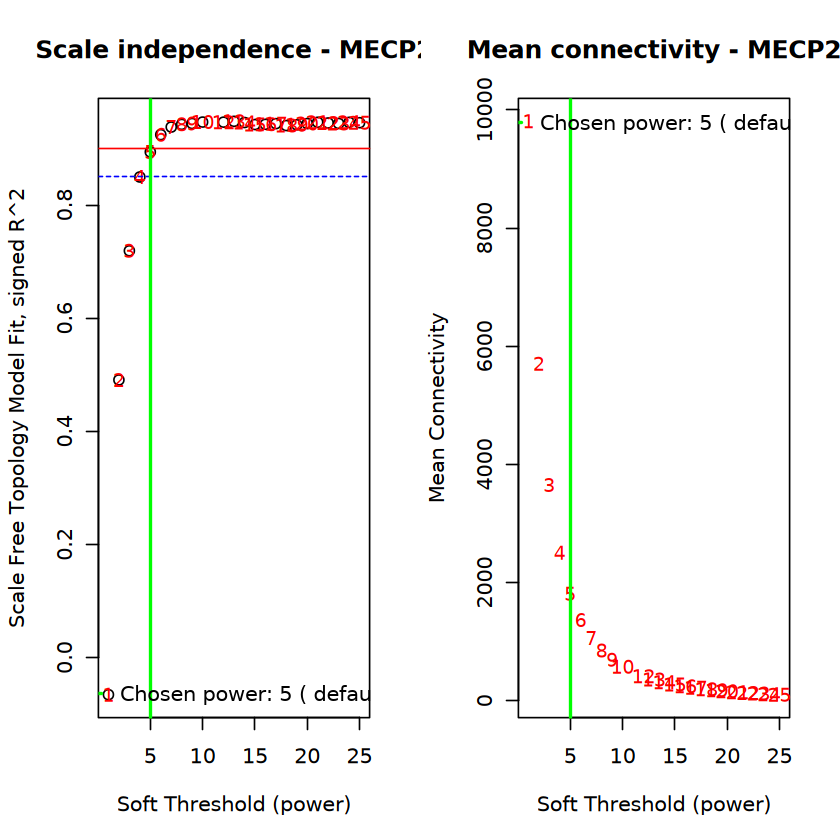

In [12]:
# Plot soft power thresholds for each cell line
for (cell_line in names(sft_results)) {
  if (!is.null(sft_results[[cell_line]])) {
    sft <- sft_results[[cell_line]]
    
    # Determine which power to use: default first, then secondary if no default
    default_power <- sft$powerEstimate
    final_power <- NA
    
    if (!is.na(default_power)) {
      final_power <- default_power
      power_source <- "default"
    } else {
      # Calculate secondary recommendation (min power with R² > 0.8)
      fit_indices <- sft$fitIndices
      R2_values <- fit_indices[, 2]
      powers <- fit_indices[, 1]
      valid_powers <- powers[R2_values > 0.8]
      
      if (length(valid_powers) > 0) {
        final_power <- min(valid_powers)
        power_source <- "secondary"
      }
    }
    
    par(mfrow = c(1, 2))
    cex1 = 0.9
    
    # Plot 1: Scale independence
    plot(sft$fitIndices[, 1],
         -sign(sft$fitIndices[, 3]) * sft$fitIndices[, 2],
         xlab = "Soft Threshold (power)",
         ylab = "Scale Free Topology Model Fit, signed R^2",
         main = paste("Scale independence -", cell_line)
    )
    text(sft$fitIndices[, 1],
         -sign(sft$fitIndices[, 3]) * sft$fitIndices[, 2],
         labels = powers, cex = cex1, col = "red"
    )
    abline(h = 0.90, col = "red")
    abline(h = 0.85, col = "blue", lty = 2)  # Add 0.85 threshold for reference
    
    # Mark the chosen power if available
    if (!is.na(final_power)) {
      abline(v = final_power, col = "green", lwd = 2)
      # Add legend to show which power was chosen and why
      legend("bottomright", 
             legend = paste("Chosen power:", final_power, "(", power_source, ")"),
             col = "green", lwd = 2, bty = "n")
    }
    
    # Plot 2: Mean connectivity
    plot(sft$fitIndices[, 1],
         sft$fitIndices[, 5],
         xlab = "Soft Threshold (power)",
         ylab = "Mean Connectivity",
         type = "n",
         main = paste("Mean connectivity -", cell_line)
    )
    text(sft$fitIndices[, 1],
         sft$fitIndices[, 5],
         labels = powers,
         cex = cex1, col = "red")
    
    # Mark the chosen power if available
    if (!is.na(final_power)) {
      abline(v = final_power, col = "green", lwd = 2)
      # Add legend to show which power was chosen and why
      legend("topright", 
             legend = paste("Chosen power:", final_power, "(", power_source, ")"),
             col = "green", lwd = 2, bty = "n")
    }
  }
}

# Reset plotting parameters
par(mfrow = c(1, 1))

### Module Generation

In [13]:
# Build Modules for each cell line using their recommended powers
networks <- list()

# Store original cor function
temp_cor <- cor       
cor <- WGCNA::cor # Force it to use WGCNA cor function

for (cell_line in names(sft_results)) {
    picked_power <- 22
    
    # Only proceed if we have a valid power
    if (!is.na(picked_power)) {
      counts_data <- datasets[[cell_line]]$counts
      
      cat(paste0("\nBuilding modules for ", cell_line, " with power = ", picked_power, " (", power_source, " recommendation)\n"))
      cat(paste0("Dataset dimensions: ", nrow(counts_data), " samples x ", ncol(counts_data), " genes\n"))
      
      netwk <- blockwiseModules(counts_data,
                                
                                # Other options
                                maxPOutliers = 0.1,
                                TOMType = "signed",
                                networkCalibration = "full quantile",
                                saveConsensusTOMs = TRUE,
                                
                                # == Adjacency Function ==
                                power = picked_power,                
                                networkType = "signed",
                                
                                # == Tree and Block Options ==
                                deepSplit = 4,
                                pamRespectsDendro = F,
                                # detectCutHeight = 0.75,
                                minModuleSize = 20,
                                maxBlockSize = 4000,
                                
                                # == Module Adjustments ==
                                reassignThreshold = 0,
                                mergeCutHeight = 0.1,
                                
                                # == TOM == Archive the run results in TOM file
                                saveTOMs = T,
                                saveTOMFileBase = paste0("TOM_", cell_line),
                                
                                # == Output Options
                                numericLabels = T,
                                verbose = 3)
      
      networks[[cell_line]] <- netwk
      
      cat(paste0("Completed module building for ", cell_line, "\n"))
      cat(paste0("Number of modules: ", length(unique(netwk$colors)), "\n"))
    } else {
      cat(paste0("Skipping ", cell_line, " - no valid power estimate available\n"))
    }
}

# Return cor function to original namespace
cor <- temp_cor


Building modules for MECP2 with power = 22 (default recommendation)
Dataset dimensions: 32 samples x 19577 genes
 Calculating module eigengenes block-wise from all genes
   Flagging genes and samples with too many missing values...
    ..step 1
 ....pre-clustering genes to determine blocks..
   Projective K-means:
   ..k-means clustering..
   ..merging smaller clusters...
Block sizes:
gBlocks
   1    2    3    4    5 
3997 3997 3991 3915 3677 
 ..Working on block 1 .
    TOM calculation: adjacency..
    ..will use 20 parallel threads.
     Fraction of slow calculations: 0.000000
    ..connectivity..
    ..matrix multiplication (system BLAS)..
    ..normalization..
    ..done.
   ..saving TOM for block 1 into file TOM_MECP2-block.1.RData
 ....clustering..
 ....detecting modules..
 ....calculating module eigengenes..
 ....checking kME in modules..
     ..removing 10 genes from module 1 because their KME is too low.
     ..removing 1 genes from module 2 because their KME is too low.
 ..W

In [14]:
# Iterate through each cell line and save module distributions
module_summaries <- list()

for (cell_line in names(networks)) {
  if (!is.null(networks[[cell_line]])) {
    cat(paste0("\nProcessing module distribution for: ", cell_line, "\n"))
    
    # Convert numeric module labels to module colors
    mergedColors <- labels2colors(networks[[cell_line]]$colors)
    
    # View module distribution as a table (number of genes per module)
    module_dist <- as.data.frame(table(mergedColors))
    module_dist <- module_dist[order(module_dist$Freq, decreasing = TRUE), ]
    colnames(module_dist) <- c("Module", "Genes")
    
    # Number of modules
    n_modules <- nrow(module_dist)
    cat(paste0("Number of modules: ", n_modules, "\n"))
    print(head(module_dist))
    
    # Save output with cell line-specific filename
    output_file <- paste0("08_WGCNA/", cell_line, "_gene_module_distribution.csv")
    write.csv(module_dist, output_file, row.names = FALSE)
    cat(paste0("Saved: ", output_file, "\n"))
    
    # Store summary information
    module_summaries[[cell_line]] <- list(
      n_modules = n_modules,
      total_genes = sum(module_dist$Genes),
      module_sizes = module_dist$Genes,
      largest_module = max(module_dist$Genes),
      smallest_module = min(module_dist$Genes)
    )
  }
}


Processing module distribution for: MECP2
Number of modules: 69
      Module Genes
64 turquoise  3971
23      grey  3882
4       blue  2723
5      brown  1367
67    yellow  1082
21     green   501
Saved: 08_WGCNA/MECP2_gene_module_distribution.csv


In [15]:
# Save dendrograms
for (cell_line in names(networks)) {
  if (!is.null(networks[[cell_line]])) {
    pdf(paste0("08_WGCNA/", cell_line, "_dendrogram.pdf"), width = 12, height = 8)
    
    mergedColors <- labels2colors(networks[[cell_line]]$colors)
    
    plotDendroAndColors(
      networks[[cell_line]]$dendrograms[[1]],
      mergedColors[networks[[cell_line]]$blockGenes[[1]]],
      main = paste("Gene Clustering -", cell_line),
      dendroLabels = FALSE,
      hang = 0.03,
      addGuide = TRUE,
      guideHang = 0.05
    )
    
    dev.off()
    cat(paste0("Saved: 08_WGCNA/", cell_line, "_dendrogram.pdf\n"))
  }
}

Saved: 08_WGCNA/MECP2_dendrogram.pdf


In [16]:
# Create and save module assignments for all cell lines
module_assignments <- list()

for (cell_line in names(networks)) {
  if (!is.null(networks[[cell_line]])) {
    cat(paste0("Processing module assignments for: ", cell_line, "\n"))
    
    # Pull out list of modules
    module_df <- data.frame(
      gene_id = colnames(datasets[[cell_line]]$counts),
      module_number = networks[[cell_line]]$colors,
      module_color = labels2colors(networks[[cell_line]]$colors)
    )
    
    # Sort by module number
    module_df <- module_df[order(module_df$module_number), ]
    
    # Save module assignments
    output_file <- paste0("08_WGCNA/", cell_line, "_gene_modules.txt")
    write.table(module_df, file = output_file, sep = "\t", row.names = FALSE, quote = FALSE)
    cat(paste0("Saved: ", output_file, "\n"))
    
    # Store in list for potential later use
    module_assignments[[cell_line]] <- module_df
    
    # Show summary
    n_modules <- length(unique(module_df$module_color))
    cat(paste0("Number of modules: ", n_modules, "\n"))
    print(head(module_df))
  }
}

Processing module assignments for: MECP2
Saved: 08_WGCNA/MECP2_gene_modules.txt
Number of modules: 69
              gene_id module_number module_color
A0A024R0Q4 A0A024R0Q4             0         grey
A0A024RAJ1 A0A024RAJ1             0         grey
A0A087WT20 A0A087WT20             0         grey
A0A087WT34 A0A087WT34             0         grey
A0A087WT90 A0A087WT90             0         grey
A0A087WTT2 A0A087WTT2             0         grey


### Module Eigengenes

In [17]:
# Calculate Module Eigengenes for all cell lines
MEs_list <- list()

for (cell_line in names(networks)) {
  if (!is.null(networks[[cell_line]])) {
    cat(paste0("Calculating Module Eigengenes for: ", cell_line, "\n"))
    
    # Get counts data for this cell line
    counts_data <- datasets[[cell_line]]$counts
    
    # Convert module labels to colors
    mergedColors <- labels2colors(networks[[cell_line]]$colors)
    
    # Get Module Eigengenes
    MEs0 <- moduleEigengenes(counts_data, mergedColors)$eigengenes
    
    # Reorder modules so similar modules are next to each other
    MEs0 <- orderMEs(MEs0)
    module_order <- names(MEs0) %>% gsub("ME", "", .)
    
    # Add sample names as a column
    MEs0$sample_id <- rownames(MEs0)
    
    # Store in list
    MEs_list[[cell_line]] <- MEs0
    
    # Save Module Eigengenes
    me_file <- paste0("08_WGCNA/", cell_line, "_module_eigengenes.txt")
    write.table(MEs0, file = me_file, sep = "\t", row.names = FALSE, quote = FALSE)
    cat(paste0("Saved: ", me_file, "\n"))
    
    # Show summary
    cat(paste0("Number of Module Eigengenes: ", ncol(MEs0) - 1, "\n"))  # -1 for sample_id column
    print(head(MEs0[, 1:min(6, ncol(MEs0))]))  # Show first few columns
  }
}

Calculating Module Eigengenes for: MECP2
Saved: 08_WGCNA/MECP2_module_eigengenes.txt
Number of Module Eigengenes: 69
                         MEpink MEmagenta   MEorange MElavenderblush3
CO_R270X_B1_d18_A1  0.002823449 0.1258319 0.10469035        0.1311128
CO_R270X_B1_d18_A2 -0.005626526 0.1129932 0.08950843        0.2007168
CO_R270X_B1_d18_A3 -0.009269397 0.1068721 0.06816713        0.1596962
CO_R270X_B1_d18_D1  0.056610933 0.1736676 0.15314122        0.2594875
CO_R270X_B1_d18_D2  0.010250562 0.1303987 0.12006893        0.2875670
CO_R270X_B1_d18_D3 -0.001516490 0.1256273 0.13218924        0.2724687
                   MEmediumorchid MEdarkturquoise
CO_R270X_B1_d18_A1     0.04044336   -0.0008011992
CO_R270X_B1_d18_A2     0.10573560   -0.1026139157
CO_R270X_B1_d18_A3     0.06123052   -0.0779250899
CO_R270X_B1_d18_D1     0.13306242    0.0171832797
CO_R270X_B1_d18_D2     0.10632790   -0.1236268993
CO_R270X_B1_d18_D3     0.12930041   -0.1283232616


In [18]:
# Calculate Module Membership for all cell lines
MM_list <- list()

for (cell_line in names(networks)) {
  if (!is.null(networks[[cell_line]]) && !is.null(MEs_list[[cell_line]])) {
    cat(paste0("Calculating Module Membership for: ", cell_line, "\n"))
    
    # Get counts data and MEs for this cell line
    counts_data <- datasets[[cell_line]]$counts
    MEs <- MEs_list[[cell_line]]
    
    # Extract just the ME values (remove sample_id column)
    me_values <- MEs[, !colnames(MEs) %in% "sample_id"]
    rownames(me_values) <- MEs$sample_id
    
    # Calculate module membership (bicor correlation between genes and MEs)
    moduleMembership <- bicorAndPvalue(counts_data, me_values,
                                      alternative = "two.sided", 
                                      use = "pairwise.complete.obs",
                                      maxPOutliers = 0.1)
    
    # Extract correlation values
    MM_cor <- as.data.frame(moduleMembership$bicor)
    colnames(MM_cor) <- gsub(pattern = "ME", replacement = "", x = colnames(MM_cor), fixed = TRUE)
    MM_cor$gene_id <- rownames(MM_cor)
    
    # Extract p-values
    MM_pval <- as.data.frame(moduleMembership$p)
    colnames(MM_pval) <- paste0(gsub(pattern = "ME", replacement = "", x = colnames(MM_pval), fixed = TRUE), "_pvalue")
    MM_pval$gene_id <- rownames(MM_pval)
    
    # Merge correlation and p-values
    MM <- merge(MM_cor, MM_pval, by = "gene_id")
    
    # Add module assignment
    mergedColors <- labels2colors(networks[[cell_line]]$colors)
    module_assign <- data.frame(gene_id = colnames(counts_data), 
                               module_color = mergedColors)
    MM <- merge(MM, module_assign, by = "gene_id")
    
    # Reorder columns
    mm_cols <- c("gene_id", "module_color")
    other_cols <- setdiff(colnames(MM), mm_cols)
    MM <- MM[, c(mm_cols, other_cols)]
    
    # Store in list
    MM_list[[cell_line]] <- MM
    
    # Save Module Membership
    mm_file <- paste0("08_WGCNA/", cell_line, "_module_membership.txt")
    write.table(MM, file = mm_file, sep = "\t", row.names = FALSE, quote = FALSE)
    cat(paste0("Saved: ", mm_file, "\n"))
    
    # Show summary
    cat(paste0("Module Membership dimensions: ", nrow(MM), " genes x ", ncol(MM), " columns\n"))
    print(head(MM[, 1:min(6, ncol(MM))]))
  }
}

Calculating Module Membership for: MECP2


Warning message in bicor(x, y, use = use, ...):
“bicor: zero MAD in variable 'x'. Pearson correlation was used for individual columns with zero (or missing) MAD.”


Saved: 08_WGCNA/MECP2_module_membership.txt
Module Membership dimensions: 19577 genes x 140 columns
     gene_id module_color       pink    magenta     orange lavenderblush3
1 A0A024R0Q4         grey -0.1075571 -0.2751148 -0.1260996     0.07932988
2 A0A024R5G2  lightyellow -0.1639888  0.4202165  0.2012794    -0.08309121
3 A0A024RAA5    turquoise -0.3644478 -0.6785778 -0.5802587    -0.30578132
4 A0A024RAJ1         grey  0.3703571  0.3774304  0.4118850     0.33406078
5 A0A024RBW1         blue  0.1463515  0.7554138  0.6208566     0.51595564
6 A0A024RDL5   lightgreen -0.3876571 -0.5347382 -0.5556219    -0.60381516


### Get Module Hub Genes

In [19]:
# Identify hub genes for all cell lines
hub_genes_all <- list()

for (cell_line in names(MM_list)) {
  if (!is.null(MM_list[[cell_line]])) {
    cat(paste0("Identifying hub genes for: ", cell_line, "\n"))
    
    MM <- MM_list[[cell_line]]
    
    # Get module colors (excluding grey and any non-module columns)
    module_cols <- colnames(MM)[!colnames(MM) %in% c("gene_id", "module_color") & 
                                 !grepl("_pvalue$|_FDR$", colnames(MM))]
    
    # Get hub genes for each module
    hubGenes <- sapply(module_cols, function(x) {
      # Check if this is actually a module (should match module_color values)
      if (x %in% MM$module_color) {
        temp <- MM[MM$module_color == x, ]
        # Get gene with maximum correlation to the module
        if (nrow(temp) > 0 && x %in% colnames(temp)) {
          max_cor <- max(temp[, x], na.rm = TRUE)
          hub_gene <- temp$gene_id[temp[, x] == max_cor] %>% as.character() %>% unique() %>% sort()
          return(hub_gene)
        }
      }
      return(NA)
    })
    
    # Remove NULL/NA entries and grey module
    hubGenes <- hubGenes[!is.na(hubGenes)]
    hubGenes$grey <- NULL
    
    # Convert to data frame
    hub_df <- data.frame(
      module = names(hubGenes),
      hub_gene = unlist(hubGenes),
      cell_line = cell_line
    )
    
    # Add correlation value
    for (i in 1:nrow(hub_df)) {
      module <- hub_df$module[i]
      gene <- hub_df$hub_gene[i]
      hub_df$correlation[i] <- MM[MM$gene_id == gene & MM$module_color == module, module]
    }
    
    # Store in list
    hub_genes_all[[cell_line]] <- hub_df
    
    # Save hub genes for this cell line
    hub_file <- paste0("08_WGCNA/", cell_line, "_hub_genes.csv")
    write.csv(hub_df, hub_file, row.names = FALSE)
    cat(paste0("Saved: ", hub_file, "\n"))
    
    # Show summary
    cat(paste0("Number of hub genes identified: ", nrow(hub_df), "\n"))
    print(head(hub_df))
  }
}

Identifying hub genes for: MECP2


Warning message in hubGenes$grey <- NULL:
“Coercing LHS to a list”


Saved: 08_WGCNA/MECP2_hub_genes.csv
Number of hub genes identified: 68
                       module hub_gene cell_line correlation
pink                     pink   Q76M96     MECP2   0.9464884
magenta               magenta   Q99732     MECP2   0.9843221
orange                 orange   Q2M1Z3     MECP2   0.9728522
lavenderblush3 lavenderblush3   Q7Z3E5     MECP2   0.9383247
mediumorchid     mediumorchid   P43220     MECP2   0.9368381
darkturquoise   darkturquoise   U5Z487     MECP2   0.9606114


### Module Trait Correlation (Correlate Module Eigengene Values to Traits)

In [20]:
# First, run the module-trait correlation analysis
module_trait_results <- list()

for (cell_line in names(MEs_list)) {
  if (!is.null(MEs_list[[cell_line]]) && !is.null(datasets[[cell_line]]$metadata)) {
    cat(paste0("Performing module-trait correlation for: ", cell_line, "\n"))
    
    # Get MEs and metadata
    MEs <- MEs_list[[cell_line]]
    metadata <- datasets[[cell_line]]$metadata
    
    # Extract just the ME values (remove sample_id column)
    me_values <- MEs[, !colnames(MEs) %in% "sample_id"]
    rownames(me_values) <- MEs$sample_id
    
    # Confirm sample order matches
    sample_match <- all(rownames(me_values) == rownames(metadata))
    cat(paste0("Sample order matches: ", sample_match, "\n"))
    
    if (!sample_match) {
      metadata <- metadata[rownames(me_values), ]
      cat("Reordered metadata to match MEs\n")
    }
    
    # Remove any non-numeric columns from metadata
    numeric_metadata <- metadata[, sapply(metadata, is.numeric)]
    
    # Pearson correlation
    moduleTraitCorP <- WGCNA::cor(me_values, numeric_metadata, method = "pearson", use = "pairwise.complete.obs")
    moduleTraitPvalueP <- corPvalueFisher(moduleTraitCorP, nrow(metadata), twoSided = TRUE)
    
    # Remove unwanted columns if they exist
    cols_to_remove <- c("Treatment", "Sex", "sample_id")
    moduleTraitCorP <- moduleTraitCorP[, !colnames(moduleTraitCorP) %in% cols_to_remove, drop = FALSE]
    moduleTraitPvalueP <- moduleTraitPvalueP[, !colnames(moduleTraitPvalueP) %in% cols_to_remove, drop = FALSE]
    
    # Remove any rows that are all NA
    na_rows <- apply(moduleTraitCorP, 1, function(x) all(is.na(x)))
    moduleTraitCorP <- moduleTraitCorP[!na_rows, , drop = FALSE]
    moduleTraitPvalueP <- moduleTraitPvalueP[!na_rows, , drop = FALSE]
    
    # Store results
    module_trait_results[[cell_line]] <- list(
      correlation = moduleTraitCorP,
      pvalue = moduleTraitPvalueP
    )
  }
}

Performing module-trait correlation for: MECP2
Sample order matches: TRUE


In [21]:
# Identify significant module-trait associations
significant_associations <- list()

for (cell_line in names(module_trait_results)) {
  result <- module_trait_results[[cell_line]]
  cor_matrix <- result$correlation
  pval_matrix <- result$pvalue
  
  # Find significant correlations (p < 0.05)
  sig_indices <- which(pval_matrix < 0.05, arr.ind = TRUE)
  
  if (length(sig_indices) > 0) {
    sig_associations <- data.frame(
      cell_line = cell_line,
      module = rownames(cor_matrix)[sig_indices[, 1]],
      trait = colnames(cor_matrix)[sig_indices[, 2]],
      correlation = cor_matrix[sig_indices],
      pvalue = pval_matrix[sig_indices]
    )
    
    # Sort by absolute correlation
    sig_associations <- sig_associations[order(-abs(sig_associations$correlation)), ]
    
    significant_associations[[cell_line]] <- sig_associations
    
    # Save significant associations
    sig_file <- paste0("08_WGCNA/", cell_line, "_significant_associations.txt")
    write.table(sig_associations, sig_file, sep = "\t", row.names = FALSE, quote = FALSE)
    cat(paste0("Saved significant associations: ", sig_file, "\n"))
    
    cat(paste0("Significant associations for ", cell_line, ": ", nrow(sig_associations), "\n"))
    print(head(sig_associations))
  } else {
    cat(paste0("No significant associations found for ", cell_line, "\n"))
  }
}

Saved significant associations: 08_WGCNA/MECP2_significant_associations.txt
Significant associations for MECP2: 141
    cell_line   module                      trait correlation       pvalue
34      MECP2 MEcoral2          D46_MUT_vs_D46_WT   0.9955016 1.592739e-60
7       MECP2 MEcoral2          D18_MUT_vs_D18_WT   0.9936782 3.905115e-54
51      MECP2 MEcoral2          D90_MUT_vs_D90_WT   0.9909054 1.056025e-47
85      MECP2 MEcoral2      Smaller_Organoid_Area   0.9909054 1.056025e-47
117     MECP2 MEcoral2 Impaired_Neurite_Outgrowth   0.9909054 1.056025e-47
77      MECP2 MEcoral2 Decreased_FOXG1_Expression   0.9690483 4.997165e-29


In [22]:
# Function to create heatmap
create_module_trait_heatmap <- function(cor_matrix, pval_matrix, cell_line) {
  # Calculate dynamic dimensions based on data size
  n_modules <- nrow(cor_matrix)
  n_traits <- ncol(cor_matrix)
  
  # Adjust plot dimensions based on data size
  plot_width <- max(10, min(18, n_traits * 0.8 + 7))
  plot_height <- max(10, min(22, n_modules * 0.5 + 9))
    
  # Create significance asterisks
  star <- apply(pval_matrix, 2, function(x) {
    sapply(x, function(y) {
      ifelse(y < 0.001, "***", 
             ifelse(y < 0.01, "**", 
                    ifelse(y < 0.05, "*", "")))
    })
  })
  
  # Set up PDF
  pdf_file <- paste0("08_WGCNA/", cell_line, "_module_trait_heatmap.pdf")
  pdf(pdf_file, width = plot_width, height = plot_height)
  
  # Use a 2x2 grid layout for control adding legends
  layout(matrix(c(1, 1, 2, 3), 2, 2, byrow = TRUE), 
         widths = c(0.85, 0.15),  # 85% heatmap, 15% legends
         heights = c(0.9, 0.1))  # 90% heatmap, 10% bottom space
  
  # Main heatmap plot
  par(mar = c(
    max(12, n_traits * 1.1), 
    max(6, n_modules * 0.15), 
    6,                      
    2                        
  ))
  
  # Adjust text size
  cex_text <- ifelse(n_modules > 50, 0.8, 
                    ifelse(n_modules > 30, 0.9, 1.0))
  
  cex_labels <- ifelse(n_traits > 15, 0.7, 
                      ifelse(n_traits > 10, 0.8, 0.9))
  
  # Plot the heatmap
  labeledHeatmap(
    Matrix = cor_matrix,
    xLabels = colnames(cor_matrix),
    xLabelsAngle = 90, 
    xLabelsAdj = c(1, 0.5),
    yLabels = rownames(cor_matrix),
    ySymbols = gsub("ME", "", rownames(cor_matrix)),
    colorLabels = FALSE,
    colors = blueWhiteRed(50),
    textMatrix = star,
    setStdMargins = FALSE,
    cex.text = cex_text, 
    textAdj = c(0.5, 0.8),
    zlim = c(-1, 1),
    main = paste("Module-Trait Correlation -", cell_line),
    cex.lab.x = cex_labels, 
    cex.lab.y = cex_labels,
    plotLegend = FALSE, 
    xLabelsPosition = "bottom"
  )
  
  # Color legend
  par(mar = c(3, 2, 3, 4))
  plot.new()
  # Create custom color legend
  plot.window(xlim = c(0, 1), ylim = c(0, 1))
  gradient <- blueWhiteRed(50)
  x_pos <- seq(0.1, 0.9, length.out = 50)
  
  # Draw color gradient
  for (i in 1:50) {
    rect(x_pos[i], 0.3, x_pos[i] + 0.016, 0.7, col = gradient[i], border = NA)
  }
  
  # Add labels 
  text(x = c(0.1, 0.5, 0.9), y = 0.2, 
       labels = c("-1", "0", "1"), cex = 0.9)
  text(x = 0.5, y = 0.9, "Pearson Correlation", cex = 1.0, font = 2)
  
  # Significance legend
  par(mar = c(3, 2, 3, 4))
  plot.new()
  legend("center", 
         legend = c("*** p < 0.001", "** p < 0.01", "* p < 0.05"),
         pch = "*", 
         pt.cex = c(1.5, 1.5, 1.5),  
         cex = 0.9,              
         bty = "n",
         title = "Significance",
         title.adj = 0.5,
         ncol = 1)
  
  # Close the PDF device
  dev.off()
  
  cat(paste0("Saved heatmap: ", pdf_file, 
             " (", round(plot_width, 1), "\" x ", round(plot_height, 1), "\")\n"))
  
  return(pdf_file)
}

In [23]:
# Create heatmaps 
heatmap_files <- list()

for (cell_line in names(module_trait_results)) {
  if (!is.null(module_trait_results[[cell_line]])) {
    result <- module_trait_results[[cell_line]]
    cor_matrix <- result$correlation
    pval_matrix <- result$pvalue
    
    # Only create heatmap if there are modules and traits
    if (nrow(cor_matrix) > 0 && ncol(cor_matrix) > 0) {
      cat(paste0("Creating heatmap for: ", cell_line, "\n"))
      cat(paste0("Dimensions: ", nrow(cor_matrix), " modules x ", ncol(cor_matrix), " traits\n"))
      
      heatmap_file <- create_module_trait_heatmap(cor_matrix, pval_matrix, cell_line)
      heatmap_files[[cell_line]] <- heatmap_file
    } else {
      cat(paste0("Skipping ", cell_line, " - no modules or traits to plot\n"))
    }
  }
}

Creating heatmap for: MECP2
Dimensions: 69 modules x 7 traits
Saved heatmap: 08_WGCNA/MECP2_module_trait_heatmap.pdf (12.6" x 22")


In the above figure generate, blue is correlated with whatever we coded as 0 and red is correlated with whatever we coded as 1. Anything with a star means it's a significant correlation